# Lab session 3: Unsupervised workflows with Python

In this session, we will be focusing on two real datasets on which we will apply an unsupervised learning workflow. 

In [21]:
import pandas as pd 
import numpy as np 
from sklearn.mixture import GaussianMixture
from sklearn.cluster import KMeans, AgglomerativeClustering, SpectralClustering
import matplotlib.pyplot as plt 
import seaborn as sns 
from IPython.display import Markdown, display


## 1. Discovery on an astronomical dataset: Milky way star clustering

The APOGEE DR17 dataset contains measurement of chemical composition of stellar objects in the Milky Way. The scientific goal of clustering this dataset is to discover shared origins and differentiation from chemodynamical processes that gave rise to the current make up of our galaxy. **Globular clusters**, defined as sites of dense star formation, should contain roughly 100 stars formed at the same time and are a building block of models describing the origin of galaxy formation. Here the data is collected and aggregated in via those identified GCs based on both chemical abundance signature and proximity. 

Clustering at various granularity can offer insights towards shared origins of more distant bodies. Here, we will need to *discover* groupings from the data, and will apply external and internal validation methods as seen in the previous lab. This lab task focuses on the following three points:

1) Data modeling
2) Validation of model
3) Interpretation and communication

Reference: https://www.alphaxiv.org/abs/2506.04553

### 1. 1 Exploring the data 

The data provided has already been processed and imputated based on *Chang et al.*. You can find the details of the processing choices in table 1 which describe the selected hyperparameters based on usual astronomical data processing choices. The retained dataset's missing values were obtained via mean imputation. 

In [22]:
# Load data

astro_data = pd.read_csv("../data/astro_scaled_mean_imputed_with_ids_all.csv", index_col=0)
astro_data.head()

,C_FE,CI_FE,N_FE,O_FE,NA_FE,MG_FE,AL_FE,SI_FE,S_FE,K_FE,CA_FE,TI_FE,TIII_FE,V_FE,CR_FE,MN_FE,FE_H,CO_FE,NI_FE,split
APOGEE_ID,,,,,,,,,,,,,,,,,,,,
2M13272321-4720027,0.739977,0.527984,-0.301359,-0.158421,0.001410,-0.067187,-0.212473,-0.345558,0.826436,1.735763,-1.536296,0.693383,1.924651,-0.001154,1.566016,0.014103,-0.670311,-0.026892,0.308209,Train
2M13260174-4740335,-1.475190,-0.685948,-0.556578,0.158895,0.325634,-0.044872,-1.275101,-0.000291,0.142837,0.453296,-0.043600,-0.771999,-0.179772,0.564315,-1.564059,-0.229645,-0.974500,-1.120681,0.078507,Train
2M13260888-4721156,0.358063,0.408568,0.807203,-0.413192,0.001410,-0.833218,1.261843,0.934014,0.013766,0.710308,0.464644,-0.458069,0.194027,0.242339,-0.576453,0.014103,-0.750145,-0.006331,0.530619,Train
2M10180676-4614205,-0.454811,-0.160425,-1.290882,0.110916,-0.063736,-0.250454,-1.301353,-0.849364,-0.125471,-0.231944,-0.003116,0.144723,0.814824,-0.205381,0.333980,0.927104,0.238405,-0.288333,0.122259,Train
2M13421985+2824515,-1.331203,-0.257150,-0.843502,0.089603,1.850031,-0.448699,-0.997914,-0.770820,0.066530,-1.017030,-0.907260,0.009317,1.482950,1.011777,-0.431168,-0.575549,0.011483,-1.694164,-0.563201,Train


**Question 0.** Describe the data loaded: how many features? what is the ratio for `split`? how many observations? print out some descriptive statistics about the data? is it scaled? 

In [ ]:
# Your answer here:

<details>
<summary>Show Python solution</summary>

```python
## Solution:
# !pip install tabulate to print correctly the tables
astro_tr = astro_data[astro_data['split']=='Train']
astro_te = astro_data[astro_data['split']=='Test']
display(Markdown(astro_tr.describe().to_markdown(index=True)))
display(Markdown(astro_te.describe().to_markdown(index=True)))
```
</details>

**Question 1** Apply appropriate dimension reduction tools to the training data. Do you need further processing of the data? Vary the hyperparameters. Try at least 3 different methods.


In [ ]:
# Your code here

<details>
<summary>Show Python solution</summary>

```python
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from umap import UMAP

perp_list = [20, 30, 60, 100, 200]
ne_list = [10, 30, 50, 100]

method_list = [("PCA", PCA(n_components=2)),
    *[(f"TSNE_perplexity_{perp}", TSNE(n_components=2, perplexity=perp, random_state=123)) for perp in perp_list], # * unpacks the lists
    *[(f"UMAP_neighbors_{nei}", UMAP(n_components=2, n_neighbors=nei, random_state=123)) for nei in ne_list]]

X_tr = astro_tr.iloc[:,:-1].to_numpy()
Z_emb = {}
for name, method in method_list:
    Z_emb[name] = method.fit_transform(X_tr)
```

**Question 2** Plot out the the resulting embeddings colored by `AL_FE` and `FE_H` (two known marker of star ages).

In [57]:
# Your code here

<details>
<summary>Show Python solution</summary>

```python
fig, ax = plt.subplots(2, 5, figsize=(20, 8))
i=0
ax = ax.flatten()
for name, _ in method_list: 
    Z_tr = Z_emb[name]
    ax[i].scatter(Z_tr[:,0], Z_tr[:, 1], c=astro_tr['AL_FE'])
    ax[i].set_title(f"{name}\n GC along AL_FE")
    i+=1
fig.tight_layout()

fig, ax = plt.subplots(2, 5, figsize=(20, 8))
i=0
ax = ax.flatten()
for name, _ in method_list: 
    Z_tr = Z_emb[name]
    ax[i].scatter(Z_tr[:,0], Z_tr[:, 1], c=astro_tr['FE_H'])
    ax[i].set_title(f"{name}\n GC along FE_H")
    i+=1
fig.tight_layout()
```

</details>

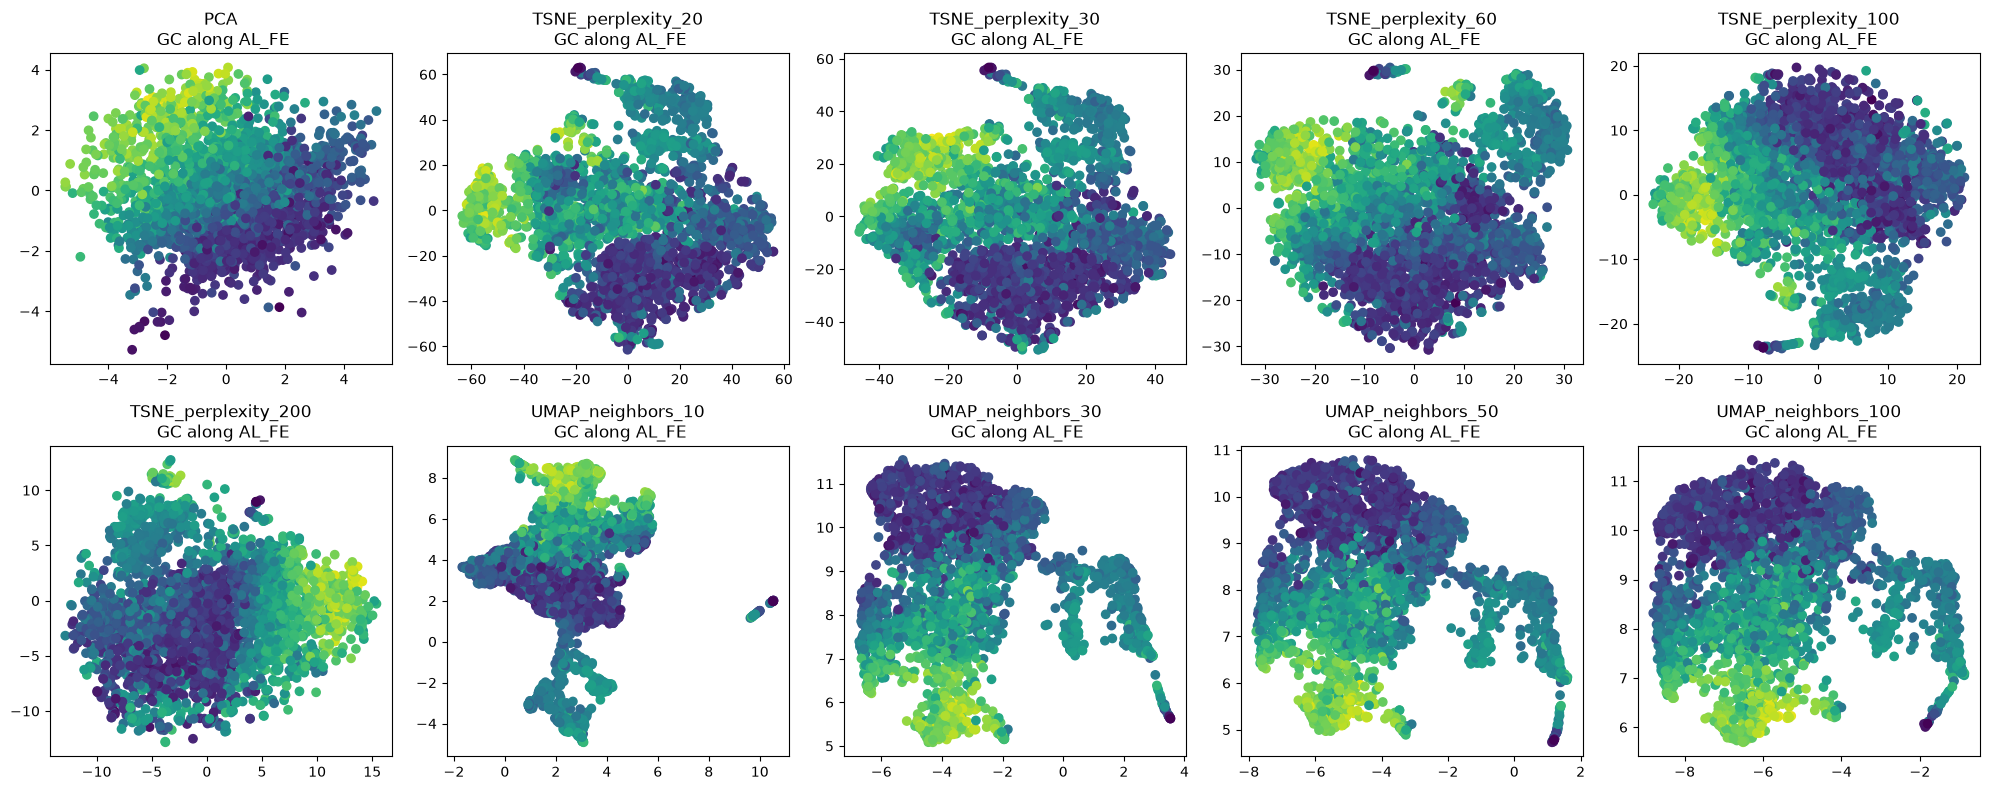

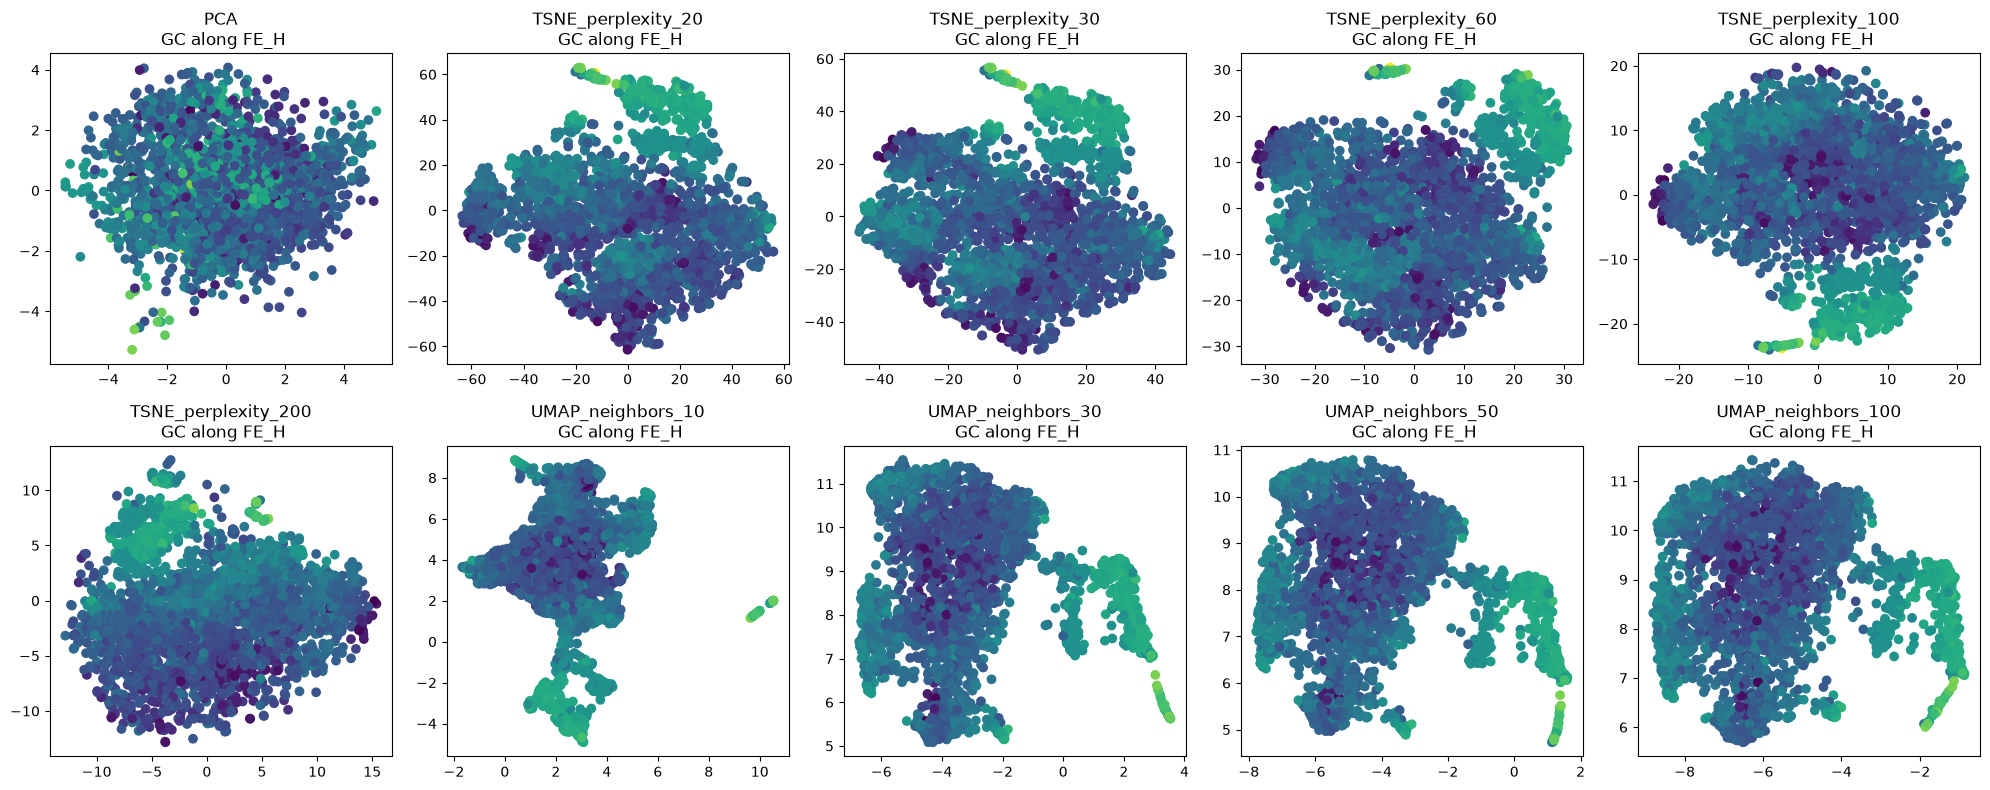

**Question 3** Choose one of the DR metric from Lab 1, and decide on the DR to choose. Does it match what you would have decided on qualitatively? Plot out the final chosen embeddings.


In [ ]:
# Your code here

<details>
<summary>Show Python solution</summary>

```python
# Solution 
from sklearn.neighbors import NearestNeighbors
from scipy.stats import pearsonr
from scipy.spatial.distance import pdist, squareform

def local_neighborhood_preservation(X, Z, k=10):
    ind_X = NearestNeighbors(n_neighbors=k + 1).fit(X).kneighbors(X, return_distance=False)[:, 1:]
    ind_Z = NearestNeighbors(n_neighbors=k + 1).fit(Z).kneighbors(Z, return_distance=False)[:, 1:]
    p_k = [len(np.intersect1d(ind_X[i], ind_Z[i])) / k for i in range(X.shape[0])]
    return np.mean(p_k)

def global_distance_preservation(X, Z):
    return pearsonr(pdist(X), pdist(Z)).statistic

def local_global(X, Z, lambda_val=3.0, k=20):
    global_d = global_distance_preservation(X, Z)
    local_d = local_neighborhood_preservation(X, Z, k)
    return local_d + lambda_val * global_d

pres = []
X_tr = astro_tr.iloc[:,:-1].to_numpy()
for name, _ in method_list:
    Z_tr = Z_emb[name]
    pres.append((name, local_global(X_tr, Z_tr, lambda_val=0.1)))
display(pres)
```

</details>

In [ ]:
# Your code here

<details>
<summary>Show Python solution</summary>

```python
# Solution:
Z_tr = Z_emb['TSNE_perplexity_20']
plt.figure(figsize=(2,2))
plt.scatter(Z_tr[:, 0], Z_tr[:, 1], s=4)
```

</details>

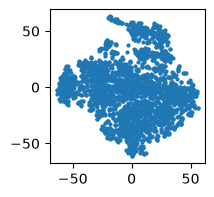

### 1.2 Modelling and validation

**Question 4** Implement `KMeans`, `AgglomerativeClustering` and `GaussianMixture` with $K=5$ at first. Make sure to use `GaussianMixture` from `sklearn.mixture`. Plot the resulting on the train split in the chosen embedding.

In [ ]:
# Your code here

<details>
<summary>Show Python solution</summary>

```python
# Solution
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture

km_5 = KMeans(n_clusters=5).fit(X_tr)
ac_5 = AgglomerativeClustering(n_clusters=5).fit(X_tr)
gmm_5 = GaussianMixture(n_components=5, init_params='k-means++', max_iter=1000).fit(X_tr)
fig, ax = plt.subplots(1, 3, figsize=(15,3))
ax[0].scatter(Z_tr[:,0], Z_tr[:, 1], c=km_5.predict(X_tr))
ax[1].scatter(Z_tr[:,0], Z_tr[:, 1], c=ac_5.fit_predict(X_tr))
ax[2].scatter(Z_tr[:,0], Z_tr[:, 1], c=gmm_5.predict(X_tr))

```

</details>

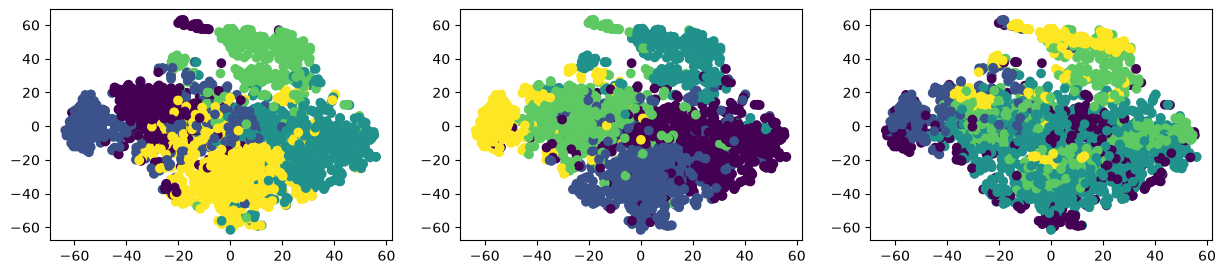

**Question 5** Use the ARI-based generalizability criterion studied in Lab 2 to choose $K$ for the clustering algorithm (external validation). Keep the two best results.

In [ ]:
# Your code here


<details>
<summary>Show Python solution</summary>

```python
# Solution 
import tqdm
from sklearn.base import clone
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import adjusted_rand_score

def generalizability(X_tr, X_te, cluster_alg, clf=None):
    if clf is None:
        clf = RandomForestClassifier(random_state=123)
    z_tr = clone(cluster_alg).fit_predict(X_tr)
    z_te = clone(cluster_alg).fit_predict(X_te)
    y_te = clone(clf).fit(X_tr, z_tr).predict(X_te)
    return adjusted_rand_score(z_te, y_te)

X_te = astro_te.iloc[:,:-1].to_numpy()
K_list = np.arange(2, 20, 1)
alg_list = {"KMeans": KMeans(random_state=123, n_init=10),
            "GaussianMixture": GaussianMixture(random_state=123, n_init=10),
            "AgglomerativeClustering": AgglomerativeClustering()}
scores = {name: {} for name in alg_list}

for i, k in tqdm.tqdm(enumerate(K_list)):
    for name, alg in alg_list.items():
        parameter = "n_components" if name == "GaussianMixture" else "n_clusters"
        model = clone(alg).set_params(**{parameter: int(k)})
        scores[name][int(k)] = generalizability(X_tr, X_te, model)
```

</details>

Plot the results as a function of $K$.

<details>
<summary>Show Python solution</summary>

```python
fig, ax = plt.subplots(1, 3, figsize=(15,3), sharey=True)
for i, name in enumerate(alg_list):
    ax[i].plot(K_list, scores[name].values(), marker='o')
    ax[i].set_title(f"{name}")
    ax[i].set_xlabel(r'$K$')
    ax[i].set_ylabel('ARI')
```

</details>

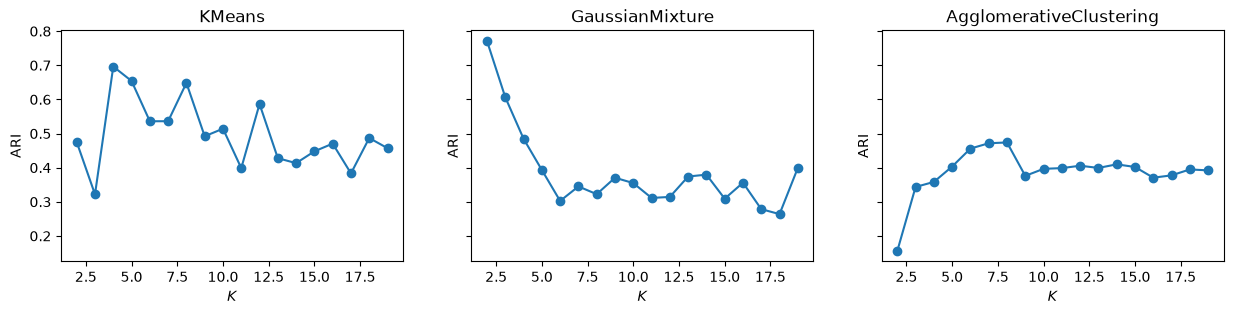

**Question 6** Plot the two best results from the previous question colored by the predicted cluster labels, and compare to the result colored by *AL_FE* and *FE_H* abundance in the embedding space.

In [ ]:
# Your code here

<details>
<summary>Show Python solution</summary>

```python
# Solution
# Gaussian mixture with K=2
gmm = GaussianMixture(n_components=2, random_state=123, n_init=10).fit(X_tr)
gmm_sol = gmm.predict(X_tr)
fig, ax = plt.subplots(2, 2, figsize=(10,8))
ax = ax.flatten()
ax[0].scatter(Z_tr[:, 0], Z_tr[:, 1], c=gmm_sol)
ax[0].set_title(r"GMM $K=2$")
ax[3].scatter(Z_tr[:, 0], Z_tr[:, 1], c=astro_tr['AL_FE'])
ax[3].set_title("AL_FE")
ax[2].scatter(Z_tr[:, 0], Z_tr[:, 1], c=astro_tr['FE_H'])
ax[2].set_title("FE_H")

# KMeans with K=4
km_sol = KMeans(n_clusters=4, random_state=123, n_init=10).fit_predict(X_tr)
ax[1].scatter(Z_tr[:, 0], Z_tr[:, 1], c=km_sol)
ax[1].set_title(r"KMeans $K=4$")
```

</details>

Text(0.5, 1.0, 'KMeans $K=4$')

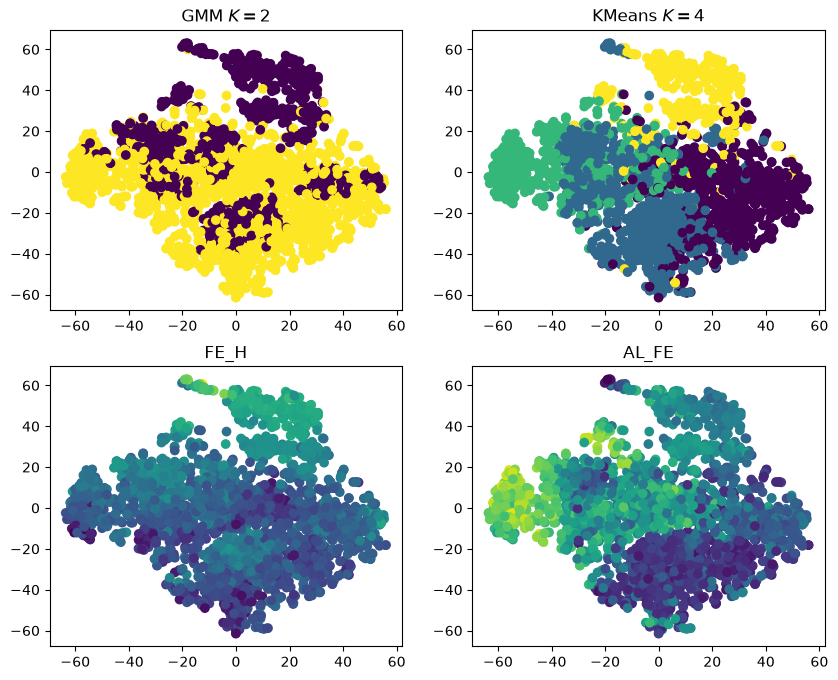

**Question 7** Clustering algorithms typically can not be re-applied on unseen data, however mixture models are *generative* and we can compute the responsibilities on unseen data (posterior probabilities sampling). Obtain the responsibilities of the clustering for a range of values of $K$, sample labels for the test points and compute the ARI against the data clustered using the same algorithm on test only. Get the best $K$ and plot out the clusters on the embedding for training and test data.

In [ ]:
# Your code here

<details>
<summary>Show Python solution</summary>

```python
ari = []
for _, K in tqdm.tqdm(enumerate(K_list)):
    gmm = GaussianMixture(n_components=K, random_state=123, n_init=10).fit(X_tr)
    prob_te = gmm.predict_proba(X_te)
    z_te = GaussianMixture(n_components=K, random_state=123, n_init=10).fit_predict(X_te)
    y_te = [np.random.choice(K, p=prob) for prob in prob_te]
    ari.append(adjusted_rand_score(y_te, z_te))

gmm = GaussianMixture(n_components=2, random_state=123, n_init=10).fit(X_tr)
fig, ax = plt.subplots(1, 2, figsize=(10,3))
ax[0].plot(K_list, ari)
y_tr = [np.random.choice(2, p=prob) for prob in gmm.predict_proba(X_tr)]
ax[1].scatter(Z_tr[:, 0], Z_tr[:, 1], c=y_tr)
```

</details>

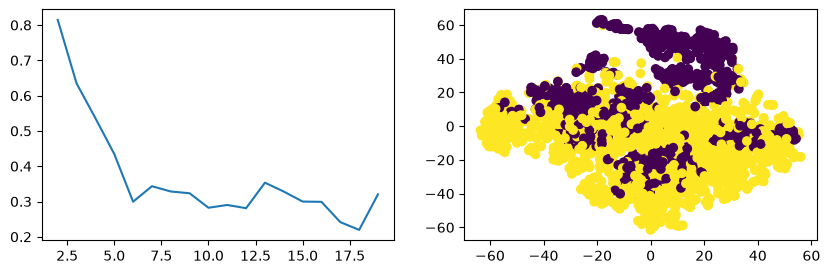

### 1.3. Results and interpretation
**Question 8** Comment on the results. 

## 2. A single-cell transcriptomics dataset example 

In this section, we will be using a classic immune cell single-cell dataset to explore clustering pipelines for cell type discovery. 

In [ ]:
# !pip install 'scanpy[leiden]' # run if needed

In [15]:
import numpy as np
import scanpy as sc

pbmc = sc.read_h5ad('../data/pbmc3k_raw.h5ad')
# Basic preprocessing : filtering poorly sequenced cells and genes
sc.pp.filter_cells(pbmc, min_genes=200)
sc.pp.filter_genes(pbmc, min_cells=3)
# Filtering out cells that are mostly dead (mitochondrial counts)
mito_genes = pbmc.var_names.str.startswith('MT-')
pbmc.obs['percent_mito'] = np.sum(pbmc[:, mito_genes].X, axis=1).A1 / np.sum(pbmc.X, axis=1).A1
pbmc.obs['n_counts'] = pbmc.X.sum(axis=1).A1
pbmc = pbmc[pbmc.obs.n_genes < 2500, :]
pbmc = pbmc[pbmc.obs.percent_mito < 0.05, :]
# Select highly variable genes BEFORE normalization 
sc.pp.highly_variable_genes(pbmc, n_top_genes=3000, flavor="seurat_v3", subset=True)


/Users/clairehe/anaconda3/envs/statgr4244/lib/python3.11/site-packages/scanpy/preprocessing/_highly_variable_genes.py:178: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns["hvg"] = {"flavor": flavor}


In [16]:
X_counts = np.array(pbmc.X.todense())
count_data = pd.DataFrame(X_counts, index=pbmc.obs_names, columns=pbmc.var_names)

# lognormalize 
sc.pp.normalize_total(pbmc, target_sum=1e4)
sc.pp.log1p(pbmc)
norm_data = pd.DataFrame(np.array(pbmc.X.todense()), index=pbmc.obs_names, columns=pbmc.var_names)

**Question 1** Reduce the dimension appropriately for the data. Color the solution with the following marker genes `NKG7`, `CST3` and `PPBP`.

In [ ]:
# Your code here 

<details>
<summary>Show Python solution</summary>

```python
# Solution

from sklearn.decomposition import PCA
Z_pca = PCA(n_components=2).fit_transform(norm_data)
fig, ax = plt.subplots(1, 3, figsize=(11, 3))
ax[0].scatter(Z_pca[:, 0], Z_pca[:, 1], c=count_data['NKG7'])
ax[0].set_title('NKG7')
ax[1].scatter(Z_pca[:, 0], Z_pca[:, 1], c=count_data['CST3'])
ax[1].set_title("CST3")
ax[2].scatter(Z_pca[:, 0], Z_pca[:, 1], c=count_data['PPBP'])
ax[2].set_title("PPBP")
```

</details>

Text(0.5, 1.0, 'PPBP')

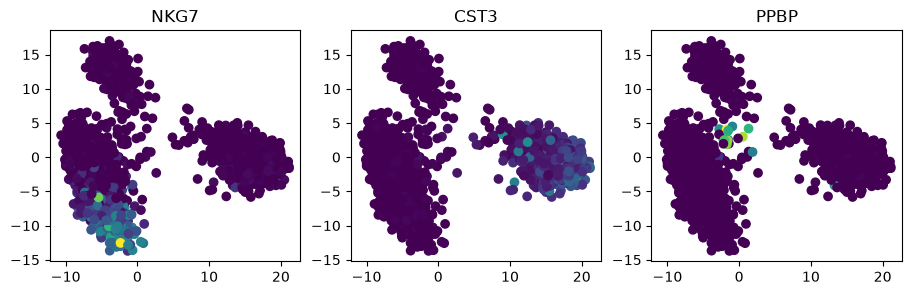

**Question 2** Cluster the raw count data and the log-normalized data using Hierachical Clustering with ward linkage. Cut the dendrogram appropriately at two different levels.

In [ ]:
# Your code

<details>
<summary>Show Python solution</summary>

```python
# Solution
from scipy.cluster.hierarchy import linkage, dendrogram
count_hc = linkage(count_data, method='ward', metric='euclidean')
log_hc = linkage(norm_data, method='ward', metric='euclidean')
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
d1 = dendrogram(count_hc, ax=ax[0])
ax[0].set_title("Count data")
d2 = dendrogram(log_hc, ax=ax[1])
ax[1].set_title("Lognormalized data")
```

</details>

Text(0.5, 1.0, 'Lognormalized data')

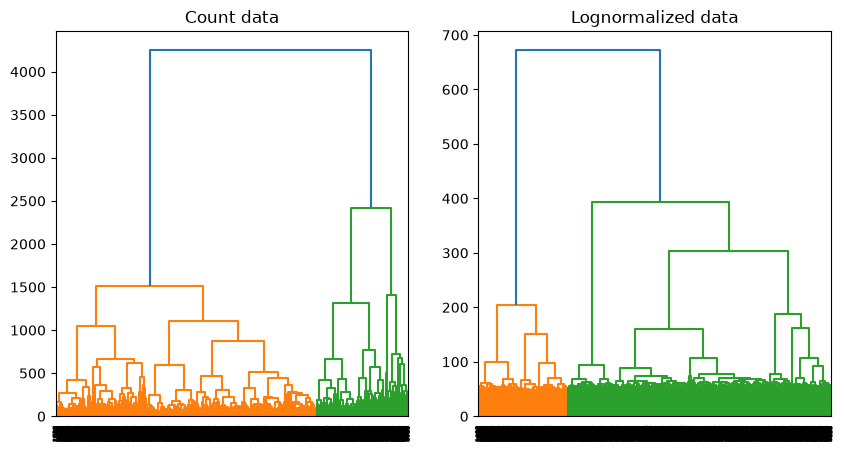

<details>
<summary>Show Python solution</summary>

```python
from scipy.cluster.hierarchy import fcluster
dist_thresh = [2000, 1000, 250, 150]
fig, ax = plt.subplots(2, 2, figsize=(8,8))
ax = ax.flatten()
for i, t in enumerate(dist_thresh):
    if i <= 1:
        y_hc = fcluster(count_hc, criterion='distance', t=t)
    else: 
        y_hc = fcluster(log_hc, criterion='distance', t=t)
    ax[i].scatter(Z_pca[:, 0], Z_pca[:, 1], c=y_hc)
    ax[i].set_title(f"Threshold {t} \n {len(np.unique(y_hc))} clusters identified")
    ax[i].set_ylabel("PC1")
    ax[i].set_xlabel("PC2")
fig.tight_layout()
```

</details>

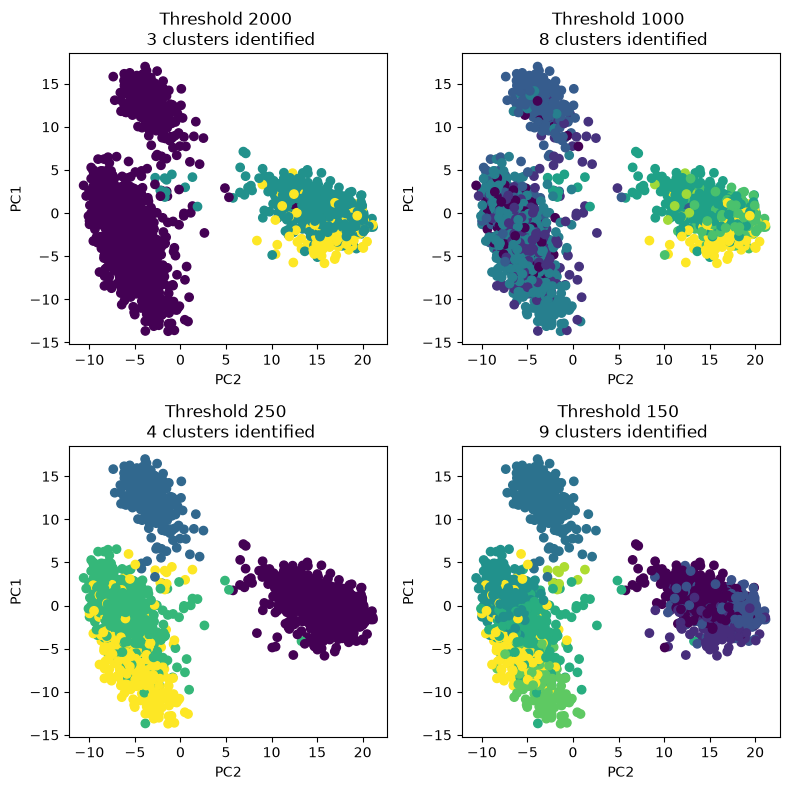

Given the following marker gene tables, we will get the gene abundance in the form of a violin plot for each marker per cluster.  


In [104]:
marker_genes = ['IL7R', 'CD79A', 'MS4A1', 'CD8B', 'LYZ', 'CD14',
                'LGALS3', 'S100A8', 'GNLY', 'NKG7', 'KLRB1',
                'FCGR3A', 'MS4A7', 'FCER1A', 'CST3', 'PPBP'] 
cluster_cuts = [
    ("Raw counts", count_hc, dist_thresh[0]),
    ("Raw counts", count_hc, dist_thresh[1]),
    ("Log-normalized", log_hc, dist_thresh[2]),
    ("Log-normalized", log_hc, dist_thresh[3]),
]


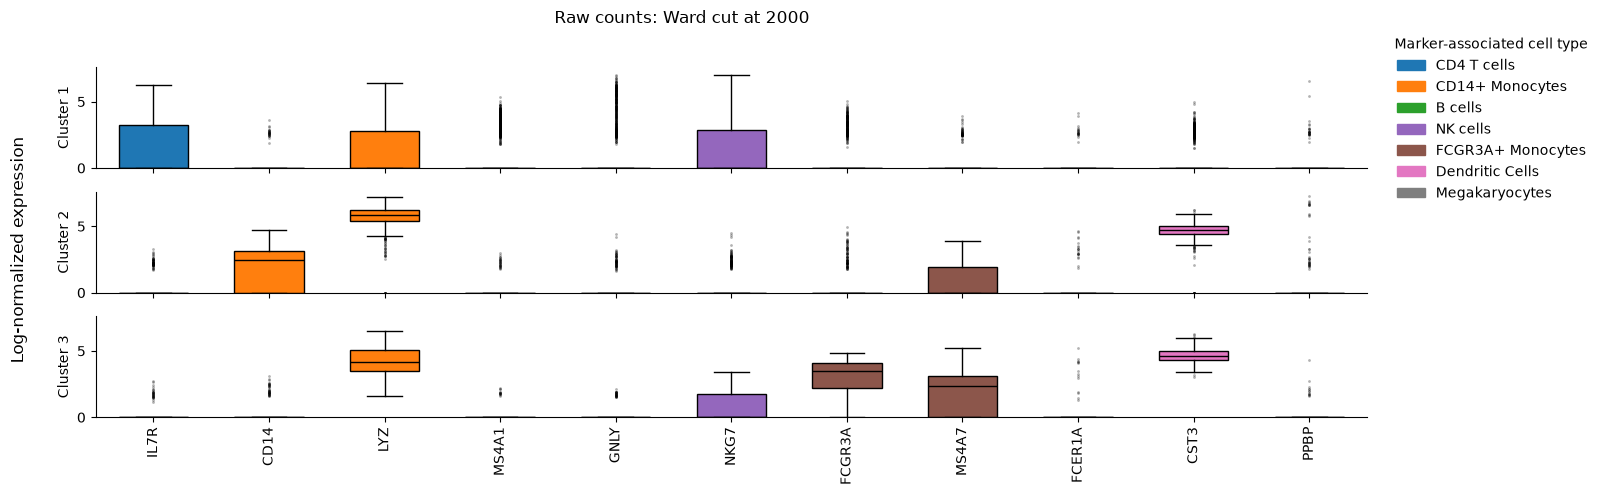

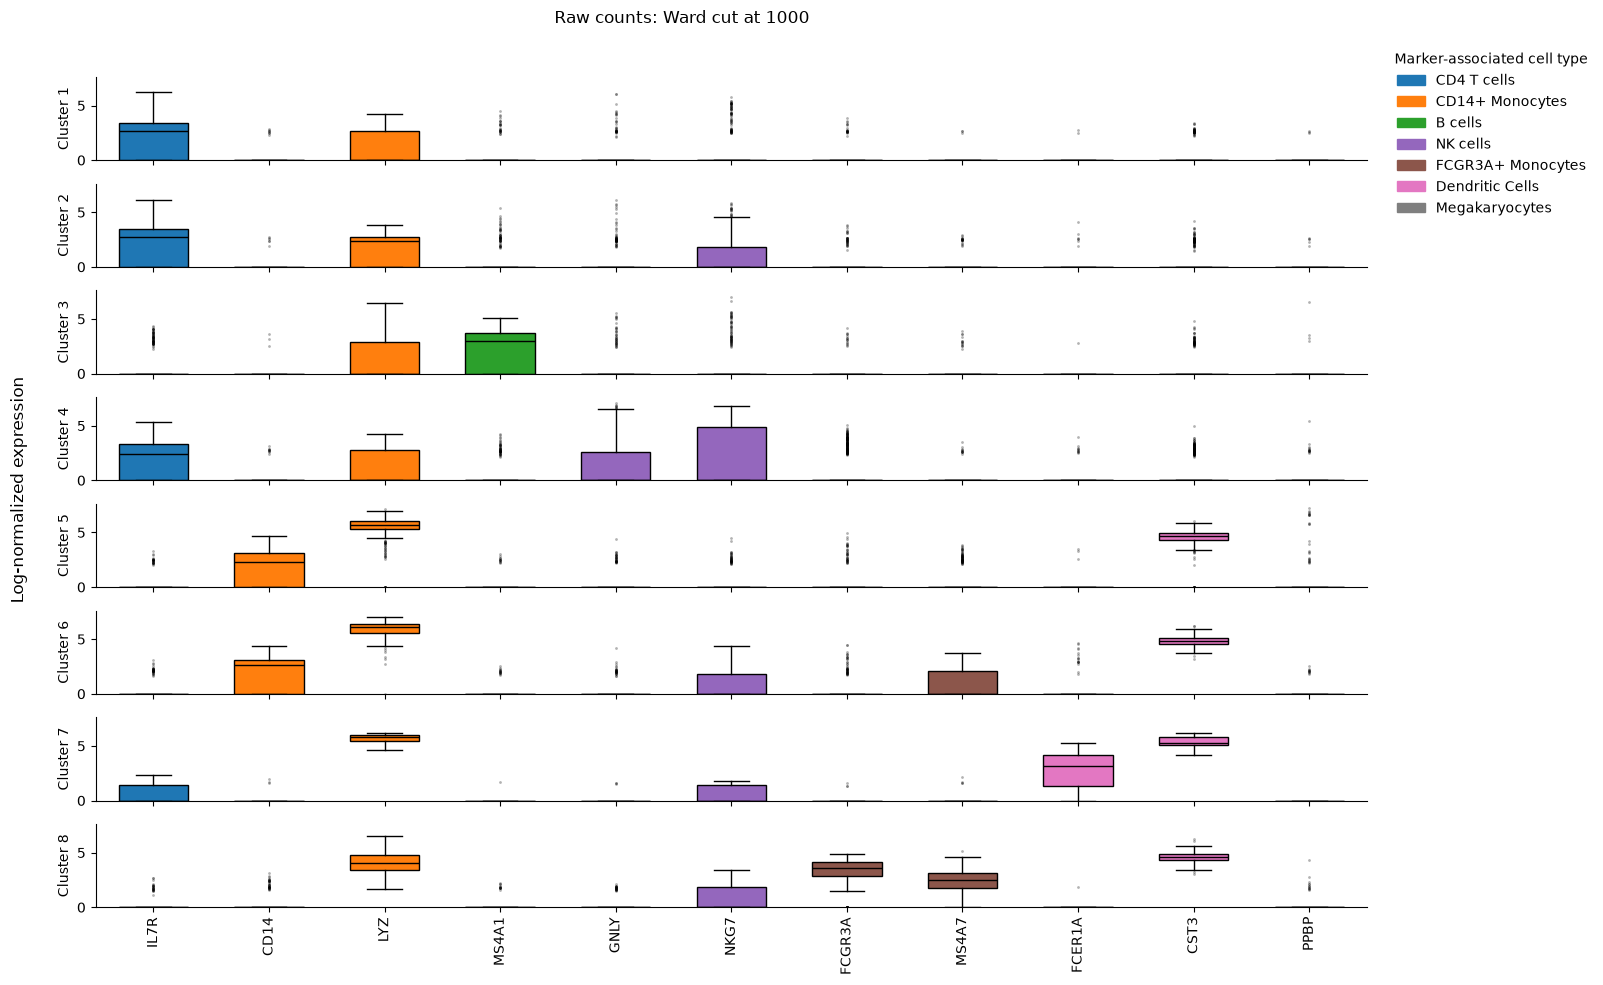

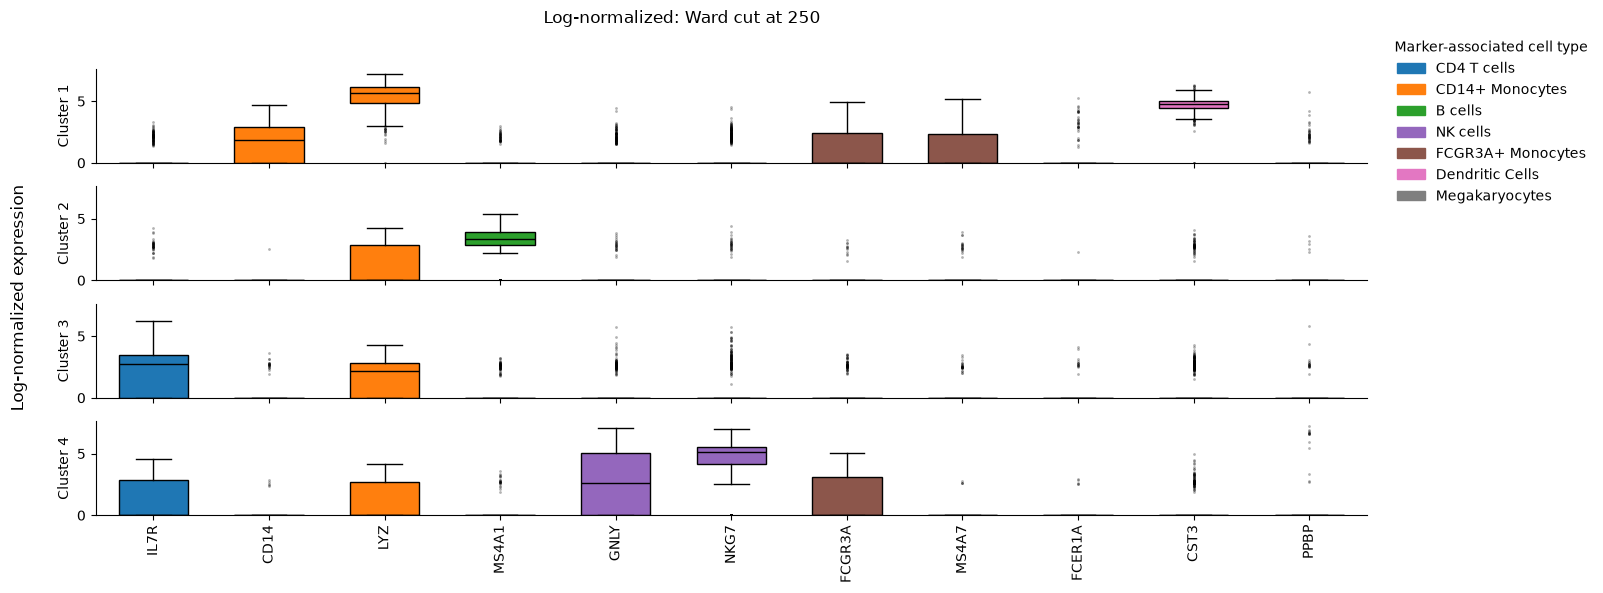

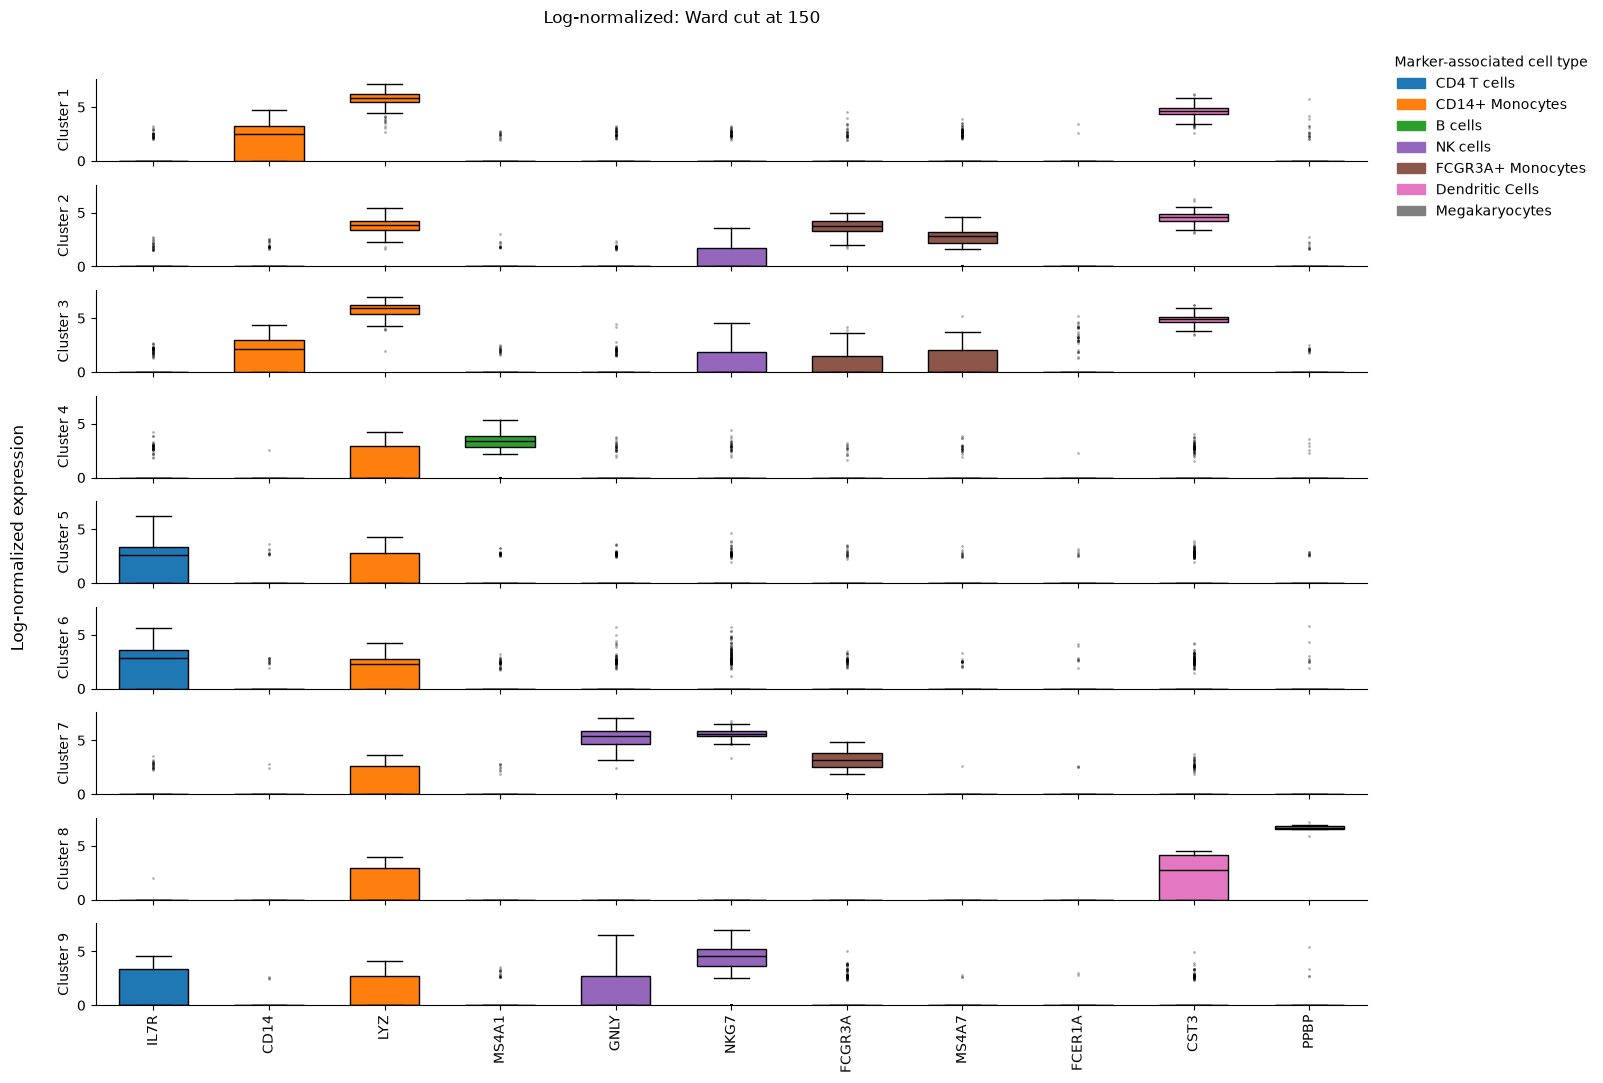

In [105]:
from scipy.cluster.hierarchy import fcluster
from matplotlib.patches import Patch

# Colors describe marker associations, not assigned cluster identities.
cell_type_markers = {
    "CD4 T cells": ["IL7R"],
    "CD14+ Monocytes": ["CD14", "LYZ"],
    "B cells": ["MS4A1"],
    "CD8 T cells": ["CD8A"],
    "NK cells": ["GNLY", "NKG7"],
    "FCGR3A+ Monocytes": ["FCGR3A", "MS4A7"],
    "Dendritic Cells": ["FCER1A", "CST3"],
    "Megakaryocytes": ["PPBP"],
}
colors = dict(zip(cell_type_markers, sns.color_palette("tab10", 8)))
gene_types = {gene: cell_type for cell_type, genes in cell_type_markers.items()
              for gene in genes if gene in norm_data.columns}
genes = list(gene_types)
if not genes:
    raise ValueError("None of the marker genes are available.")
ymax = max(norm_data[genes].to_numpy().max(), 0.1) * 1.05
legend = [Patch(color=colors[t], label=t) for t in cell_type_markers
          if t in gene_types.values()]

cuts = [("Raw counts", count_hc, t) for t in dist_thresh[:2]] + [
    ("Log-normalized", log_hc, t) for t in dist_thresh[2:]]

for name, hierarchy, threshold in cuts:
    labels = fcluster(hierarchy, t=threshold, criterion="distance")
    clusters = np.unique(labels)
    fig, axes = plt.subplots(len(clusters), 1, sharex=True, sharey=True,
                             squeeze=False, figsize=(14, max(4, len(clusters) + 2)))
    for ax, cluster in zip(axes.flat, clusters):
        boxes = ax.boxplot(norm_data.loc[labels == cluster, genes].to_numpy(),
                           patch_artist=True, widths=0.6,
                           medianprops={"color": "black"},
                           flierprops={"marker": ".", "markersize": 2, "alpha": 0.3})
        for box, gene in zip(boxes["boxes"], genes):
            box.set_facecolor(colors[gene_types[gene]])
        ax.set(ylabel=f"Cluster {cluster}", ylim=(0, ymax))
        sns.despine(ax=ax)

    axes[-1, 0].set_xticks(range(1, len(genes) + 1), genes, rotation=90)
    fig.supylabel("Log-normalized expression")
    fig.suptitle(f"{name}: Ward cut at {threshold}")
    fig.legend(handles=legend, title="Marker-associated cell type",
               loc="upper left", bbox_to_anchor=(1, 0.95), frameon=False)
    fig.tight_layout(rect=(0.02, 0, 1, 0.96))
    plt.show()
    plt.close(fig)


**Question 3** Which clustering solution would you pick based on this external validation criterion (marker abundance)? 